# Hotel Booking Cancellation Prediction | Decision Tree

Can we identify reservations at risk of cancellation before their final outcome is known?

In this project, I use a Decision Tree to predict `is_canceled` (`0` = Not Cancelled, `1` = Cancelled). I start with the raw booking data, check for leakage and repeated records, build a preprocessing pipeline, and compare an unrestricted tree with one selected through cross-validation. I also look at the errors behind the scores and inspect the rules the model learned.

**Prediction point:** This is a *pre-arrival* research experiment. Some booking details may change after the reservation is first created, so the model should not be presented as a booking-time prediction system.

**Evaluation approach:** I keep identical predictor patterns together in the train/test split and cross-validation. That makes the held-out evaluation more cautious about exact duplicates, although it cannot replace a chronological or external-hotel test.

## 1. Why a Decision Tree?

A Decision Tree makes predictions by following a series of feature-based questions. I chose it because I can inspect those questions and see which combinations of booking details the model uses.

The trade-off is overfitting: an unrestricted tree can learn rules that are too specific to the training data. Comparing it with a constrained tree lets me study that trade-off directly, rather than judging the project by one accuracy score.

### 1.1 How a Decision Tree learns

A Decision Tree builds a set of feature-based questions. After one-hot encoding, a split might look like `deposit_type_Non Refund <= 0.5` (the booking is not non-refundable) or `lead_time <= 100`. Each answer sends a reservation down a left or right branch. The process continues until the tree reaches a leaf.

At a leaf, the model predicts the class with the **largest total weighted count** among the training examples that reach it. With `class_weight=None`, this is the ordinary majority class. With `class_weight="balanced"`, scikit-learn gives more weight to examples from the less frequent class, so the predicted class is based on weighted class counts rather than raw counts alone.

**How does it choose a split?** At each node, the tree tests candidate splits and chooses the one that most reduces class impurity. A node is pure when its examples belong to only one class. The default `gini` criterion measures impurity as:

$$G = 1 - \sum_k p_k^2$$

Here, $p_k$ is the proportion of class $k$ in the node. For a simple example **without class weights**, suppose a node contains 60 not-cancelled and 40 cancelled reservations. Its Gini impurity is $1 - 0.6^2 - 0.4^2 = 0.48$. Imagine a split creates two child groups of 50:

| Child | Not cancelled / Cancelled | Gini |
|---|---|---:|
| Left | 45 / 5 | 0.18 |
| Right | 15 / 35 | 0.42 |

The weighted impurity after this split is $0.5 \times 0.18 + 0.5 \times 0.42 = 0.30$. The split therefore reduces impurity from 0.48 to 0.30, a reduction of 0.18. In general, the tree selects the candidate with the largest weighted reduction in impurity and repeats this process within each child.

The `entropy` criterion measures impurity differently:

$$H = -\sum_k p_k \log_2(p_k)$$

Entropy is zero when a node contains only one class and reaches one for a balanced binary node. With entropy, the reduction in impurity is called **information gain**: the parent node's entropy minus the weighted average entropy of its children. Gini and entropy often lead to similar splits, but they are not the same formula. The tree makes the best choice at the current node and then repeats the process; this is a **greedy** strategy, so it does not guarantee the globally best possible tree.

**Why can it overfit?** If it is left unrestricted, a tree can keep creating specific rules for small groups, including patterns that are noise rather than reliable signals. In the saved run for this project, the unrestricted tree reached a training F1 of **0.9936** but a held-out F1 of **0.7652**. After tuning, training F1 was **0.8152** and held-out F1 was **0.7897**; the train–test F1 gap fell from **0.2284** to **0.0254**. These figures illustrate the trade-off in this saved run and should be refreshed if a new split or model configuration changes the results. Limiting depth and minimum leaf size encourages broader rules that generalize better.

**Why is it interpretable?** Each prediction follows a chain of questions from the root to a leaf. Section 11 shows the first levels of the tuned tree. The trade-off is that a single tree can change noticeably when the training data changes slightly.

## 2. Libraries and plotting setup

I use pandas for data preparation, scikit-learn for modeling, and Matplotlib/Seaborn for charts. A few small helper functions keep the evaluation metrics and figure formatting consistent across the two trees.

In [1]:
# 1) Standard libraries
import colorsys
import json
from pathlib import Path

# 2) Data and plotting libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 3) Display, plotting helpers, and scikit-learn tools
from IPython.display import Markdown, display
from matplotlib.colors import LinearSegmentedColormap, to_rgb
from matplotlib.patches import Rectangle
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Keep the random choices reproducible.
RANDOM_STATE = 42

# Use the same portfolio colors in every figure.
PRIMARY = "#4C72B0"      # blue
SECONDARY = "#55A868"    # green
NEUTRAL = "#7F7F7F"      # gray
LIGHT = "#F2F2F2"

correlation_cmap = LinearSegmentedColormap.from_list(
    "portfolio_blue_green", [PRIMARY, LIGHT, SECONDARY]
)
confusion_cmap = LinearSegmentedColormap.from_list(
    "portfolio_confusion_blue_green", [PRIMARY, LIGHT, SECONDARY]
)

sns.set_theme(style="whitegrid", palette=[PRIMARY, SECONDARY, NEUTRAL])
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titlesize": 14,
    "axes.titleweight": "semibold",
    "axes.labelsize": 11,
    "savefig.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# The notebook can be run from the repository root or from the notebooks/ folder.
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
figures_dir = project_root / "images"
figures_dir.mkdir(parents=True, exist_ok=True)

# This folder is dedicated to figures from this notebook. Remove PNGs left by
# earlier runs, otherwise old charts could be mistaken for current results.
# Files of other types are not touched.
old_png_files = list(figures_dir.glob("*.png"))
for old_png in old_png_files:
    old_png.unlink()
print(f"Cleared {len(old_png_files)} previous PNG files from images/.")

# The notebook produces exactly these nine charts. Keeping an explicit list
# makes the exported figures easy to audit before publishing the project.
EXPECTED_FIGURES = {
    "cancellation_distribution.png",
    "missing_values.png",
    "correlation_matrix.png",
    "baseline_confusion_matrix.png",
    "tuned_confusion_matrix.png",
    "train_test_f1_comparison.png",
    "error_tradeoff.png",
    "tuned_tree_depth_0_to_3.png",
    "feature_importances.png",
}

# These small functions only reduce repeated plotting/metric code.
# They do not change how the model is trained.
def save_figure(fig, filename):
    """Save a project figure using one of the documented filenames."""
    if filename not in EXPECTED_FIGURES:
        raise ValueError(f"Unexpected figure name: {filename}")
    fig.savefig(figures_dir / filename, dpi=170, bbox_inches="tight", facecolor="white")


def evaluate_classifier(model_name, truth, predictions):
    """Calculate the same four classification metrics for each model."""
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(truth, predictions),
        "Precision": precision_score(truth, predictions, zero_division=0),
        "Recall": recall_score(truth, predictions, zero_division=0),
        "F1": f1_score(truth, predictions, zero_division=0),
    }


def show_confusion(truth, predictions, title, filename):
    """Plot a confusion matrix with row percentages and highlight the two error cells."""
    # Keep the label order fixed: 0 = Not Cancelled, 1 = Cancelled.
    cm = confusion_matrix(truth, predictions, labels=[0, 1])

    # Each row is divided by its actual-class total, so the percentages answer:
    # 'Of all actual examples in this class, what did the model predict?'
    row_totals = cm.sum(axis=1, keepdims=True)
    rates = np.divide(
        cm, row_totals,
        out=np.zeros_like(cm, dtype=float),
        where=row_totals != 0,
    )
    labels = np.array([
        [f"{cm[r, c]:,}\n({rates[r, c]:.1%})" for c in range(2)]
        for r in range(2)
    ])

    fig, ax = plt.subplots(figsize=(7.3, 5.6))
    sns.heatmap(
        rates,
        annot=labels,
        fmt="",
        cmap=confusion_cmap,
        vmin=0,
        vmax=1,
        linewidths=1.4,
        linecolor="white",
        square=True,
        ax=ax,
        annot_kws={"fontsize": 11, "weight": "medium"},
        xticklabels=["Not Cancelled", "Cancelled"],
        yticklabels=["Not Cancelled", "Cancelled"],
        cbar_kws={"label": "Share of actual class", "shrink": 0.82},
    )

    # The off-diagonal cells are the mistakes: false positives and false negatives.
    for row, col in [(0, 1), (1, 0)]:
        ax.add_patch(Rectangle(
            (col + 0.04, row + 0.04), 0.92, 0.92,
            fill=False, edgecolor=PRIMARY, linewidth=2.2, linestyle="--"
        ))

    ax.set_title(title, pad=14)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("Actual label")
    ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
    fig.tight_layout()
    save_figure(fig, filename)
    plt.show()
    return cm

Cleared 9 previous PNG files from images/.


## 3. Dataset and attribution

The project uses the [Hotel Booking Demand dataset on Kaggle](https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand), published there by Jesse Mostipak under CC BY 4.0. The underlying research is *Hotel Booking Demand Datasets* by Nuno António, Ana de Almeida, and Luís Nunes ([Data in Brief, DOI](https://doi.org/10.1016/j.dib.2018.11.126)).

The dataset is not redistributed with the project. For a local run, download `hotel_bookings.csv` and put it in `data/`. On Kaggle, attach the dataset through the notebook's **Add Input** option.

In [2]:
# Try the standard repository path first, then a local CSV, then Kaggle's input folders.
possible_paths = [
    Path("data/hotel_bookings.csv"),
    Path("hotel_bookings.csv"),
    Path("../data/hotel_bookings.csv"),
]
if Path("/kaggle/input").exists():
    possible_paths += list(Path("/kaggle/input").glob("**/hotel_bookings.csv"))

data_path = next((path for path in possible_paths if path.is_file()), None)
if data_path is None:
    raise FileNotFoundError(
        "hotel_bookings.csv was not found. Place it in data/ or attach it to the Kaggle notebook."
    )

# low_memory=False lets pandas infer column types using the full file more consistently.
df = pd.read_csv(data_path, low_memory=False)

# A lightweight schema check catches a wrong or incomplete input file early.
required_columns = {
    "is_canceled", "reservation_status", "reservation_status_date",
    "assigned_room_type", "company", "agent", "adults", "children", "babies",
    "stays_in_weekend_nights", "stays_in_week_nights",
}
missing_columns = required_columns - set(df.columns)
if missing_columns:
    raise ValueError(f"The dataset is missing expected columns: {sorted(missing_columns)}")
if not set(df["is_canceled"].dropna().unique()).issubset({0, 1}):
    raise ValueError("Expected is_canceled to contain only binary labels 0 and 1.")

print(f"Loaded {data_path}: {df.shape[0]:,} rows and {df.shape[1]} columns")
display(df.head(3))

Loaded ..\data\hotel_bookings.csv: 119,390 rows and 32 columns


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02


## 4. Data-quality checks

I begin by checking the column types, missing values, and exact duplicate rows. The dataset has no unique reservation identifier, so two identical records are not necessarily a data-entry mistake. Instead of deleting every repeated row, I account for repeated predictor patterns when I split the data.

In [3]:
# Count exact duplicates before making any modeling decisions.
# A duplicate row is not automatically an error: there is no unique booking ID here.
raw_duplicate_count = int(df.duplicated().sum())

# Summarize missing values so we can decide how to handle them later.
missing_summary = pd.DataFrame({
    "Missing count": df.isna().sum(),
    "Missing (%)": 100 * df.isna().mean(),
}).query("`Missing count` > 0").sort_values("Missing (%)", ascending=False)

print(f"Exact duplicate rows: {raw_duplicate_count:,} ({raw_duplicate_count / len(df):.1%})")
print("Column data types:")
print(df.dtypes.value_counts().to_string())
print("Columns with missing values:")
display(missing_summary.round(2))

Exact duplicate rows: 31,994 (26.8%)
Column data types:
int64      16
object     12
float64     4
Columns with missing values:


,Missing count,Missing (%)
company,112593,94.31
agent,16340,13.69
country,488,0.41
children,4,0.00


### 4.1 Class balance

I first look at how common cancellations are. Accuracy is useful, but it does not tell me how many cancellations the model misses or how often it raises a false alert. I therefore report **precision**, **recall**, and **F1** for the cancellation class as well.

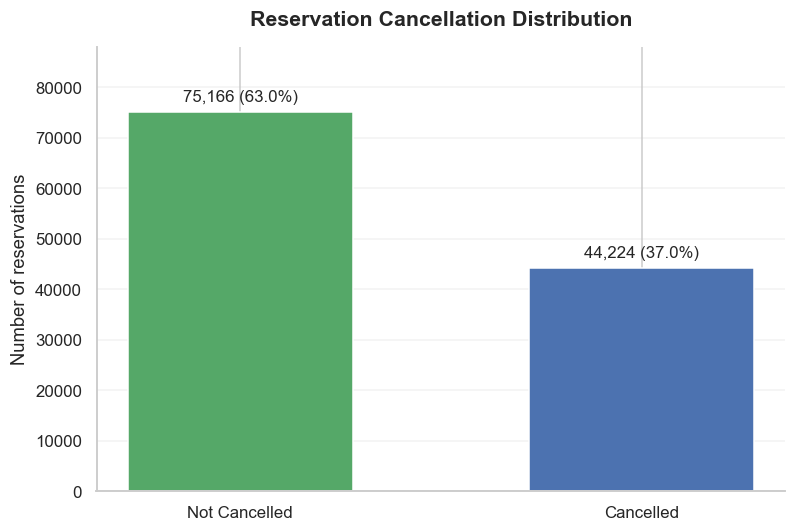

In [4]:
# Count each target class. Label 1 means the reservation was cancelled.
class_counts = df["is_canceled"].value_counts().reindex([0, 1], fill_value=0)
class_labels = ["Not Cancelled", "Cancelled"]
class_colors = [SECONDARY, PRIMARY]

fig, ax = plt.subplots(figsize=(7.4, 5))
bars = ax.bar(class_labels, class_counts.values, color=class_colors, width=0.56)
for bar, count in zip(bars, class_counts.values):
    percentage = count / len(df)
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + len(df) * 0.012,
        f"{count:,} ({percentage:.1%})",
        ha="center", va="bottom", fontsize=11,
    )
ax.set_ylim(0, class_counts.max() * 1.17)
ax.set_ylabel("Number of reservations")
ax.set_title("Reservation Cancellation Distribution", pad=14)
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
save_figure(fig, "cancellation_distribution.png")
plt.show()

### 4.2 Missing values

Missingness helps determine which fields need imputation and which deserve a closer look. In particular, `company` is mostly missing and behaves more like an identifier than a measured quantity.

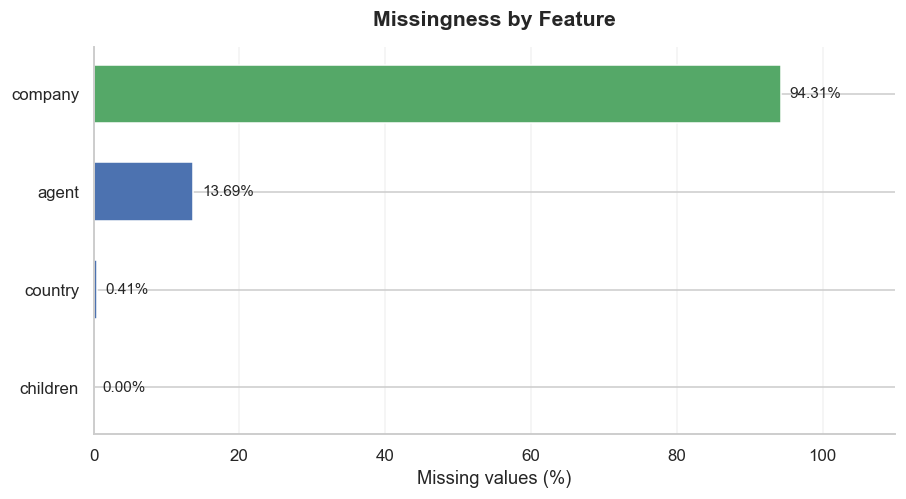

In [5]:
# Show only columns that have missing values, ordered from least to most missing.
missing_pct = missing_summary["Missing (%)"].sort_values(ascending=True)
colors = [SECONDARY if column == "company" else PRIMARY for column in missing_pct.index]

fig, ax = plt.subplots(figsize=(8.4, 4.7))
bars = ax.barh(missing_pct.index, missing_pct.values, color=colors, height=0.6)
for bar, value in zip(bars, missing_pct.values):
    ax.text(
        value + 1.2,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.2f}%",
        va="center", fontsize=10,
    )
ax.set_xlim(0, 110)
ax.set_xlabel("Missing values (%)")
ax.set_title("Missingness by Feature", pad=14)
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
save_figure(fig, "missing_values.png")
plt.show()

## 5. Feature availability and simple engineering

`reservation_status` and `reservation_status_date` describe the final booking outcome. Using them to predict cancellation would give the model information it should not have, so I remove both. I also exclude `assigned_room_type`, which may be updated later, and `company`, which is mostly missing and identifier-like.

I treat `agent` as a category rather than a number: the distance between two agent IDs has no meaning. I also create `total_nights` and `total_guests` to summarize the length of a stay and the size of a party.

Some remaining features—including `booking_changes`, `adr`, and special requests—may change during the booking lifecycle. Their availability would need to be checked against a specific scoring time before deployment.

In [6]:
# Remove fields that reveal the final outcome or may not be consistently available
# at the prediction time we want to simulate.
columns_to_drop = [
    "reservation_status",       # directly describes the final booking outcome
    "reservation_status_date",  # recorded after the outcome is known
    "assigned_room_type",       # may change later in the booking lifecycle
    "company",                  # highly missing and identifier-like
]
model_df = df.drop(columns=columns_to_drop).copy()

# Agent is an ID, not a numeric amount. Treat it as a category and label missing IDs.
model_df["agent"] = (
    model_df["agent"].astype("Int64").astype("string")
    .fillna("Unknown").astype(object)
)

# Add two easy-to-explain features that summarize the booking.
model_df["total_nights"] = (
    model_df["stays_in_weekend_nights"] + model_df["stays_in_week_nights"]
)
model_df["total_guests"] = (
    model_df["adults"] + model_df["children"].fillna(0) + model_df["babies"]
)

print("Columns removed:", columns_to_drop)
print(f"Unique agent categories: {model_df['agent'].nunique():,}")
print(f"Records with zero guests: {(model_df['total_guests'] == 0).sum():,}")
print(f"Records with zero nights: {(model_df['total_nights'] == 0).sum():,}")

Columns removed: ['reservation_status', 'reservation_status_date', 'assigned_room_type', 'company']
Unique agent categories: 334
Records with zero guests: 180
Records with zero nights: 715


## 6. Keeping identical predictor patterns together

A conventional random split could place the same set of predictor values in both training and test data. With so many repeated rows, that would make it easier for a flexible tree to recognize patterns it has effectively already seen.

I create a group label from the **predictors only**, then use `StratifiedGroupKFold` to hold out one fold. Group separation prevents exact predictor matches from crossing the split; stratification tries to keep the cancellation rates reasonably similar, although it cannot guarantee identical proportions.

This is grouping by recorded values, **not** by guest or reservation identity. I verify that no group appears on both sides.

All original rows remain in the analysis, so frequently repeated patterns still contribute more observations to the row-level metrics. Grouping changes the split, not the weight of each row.

In [7]:
# X contains the predictors; y is the outcome we want to predict.
X = model_df.drop(columns="is_canceled")
y = model_df["is_canceled"].astype(int)

# Group rows with identical predictor values. The target y is deliberately excluded.
# This stops exact predictor patterns from appearing in both train and test partitions.
predictor_hash = pd.util.hash_pandas_object(X, index=False)
groups = pd.factorize(predictor_hash, sort=False)[0]

# StratifiedGroupKFold tries to preserve the cancellation rate while keeping each
# predictor group entirely in one fold. One fold becomes the final held-out test set.
holdout_splitter = StratifiedGroupKFold(
    n_splits=5, shuffle=True, random_state=RANDOM_STATE
)
train_idx, test_idx = next(holdout_splitter.split(X, y, groups))

X_train, X_test = X.iloc[train_idx].copy(), X.iloc[test_idx].copy()
y_train, y_test = y.iloc[train_idx].copy(), y.iloc[test_idx].copy()
groups_train, groups_test = groups[train_idx], groups[test_idx]

# This check should return zero: no exact predictor group may cross the split.
shared_groups = np.intersect1d(np.unique(groups_train), np.unique(groups_test))
assert len(shared_groups) == 0, "An identical predictor group crossed train/test."

split_summary = pd.DataFrame({
    "Partition": ["Train", "Held-out test"],
    "Rows": [len(X_train), len(X_test)],
    "Cancellation rate": [y_train.mean(), y_test.mean()],
    "Unique predictor groups": [len(np.unique(groups_train)), len(np.unique(groups_test))],
})
print(f"Unique predictor patterns: {len(np.unique(groups)):,}")
print(f"Repeated predictor rows: {len(X) - len(np.unique(groups)):,}")
print(f"Shared predictor groups between train and test: {len(shared_groups)}")
display(split_summary.round(4))

Unique predictor patterns: 85,856
Repeated predictor rows: 33,534
Shared predictor groups between train and test: 0


,Partition,Rows,Cancellation rate,Unique predictor groups
0,Train,95648,0.374,68652
1,Held-out test,23742,0.356,17204


### 6.1 Pearson correlations on training data

This heatmap is a descriptive look at numerical relationships, not a feature-selection step. I calculate it using the training partition only. A correlation near zero means little *linear* association; a Decision Tree can still use nonlinear relationships or interactions.

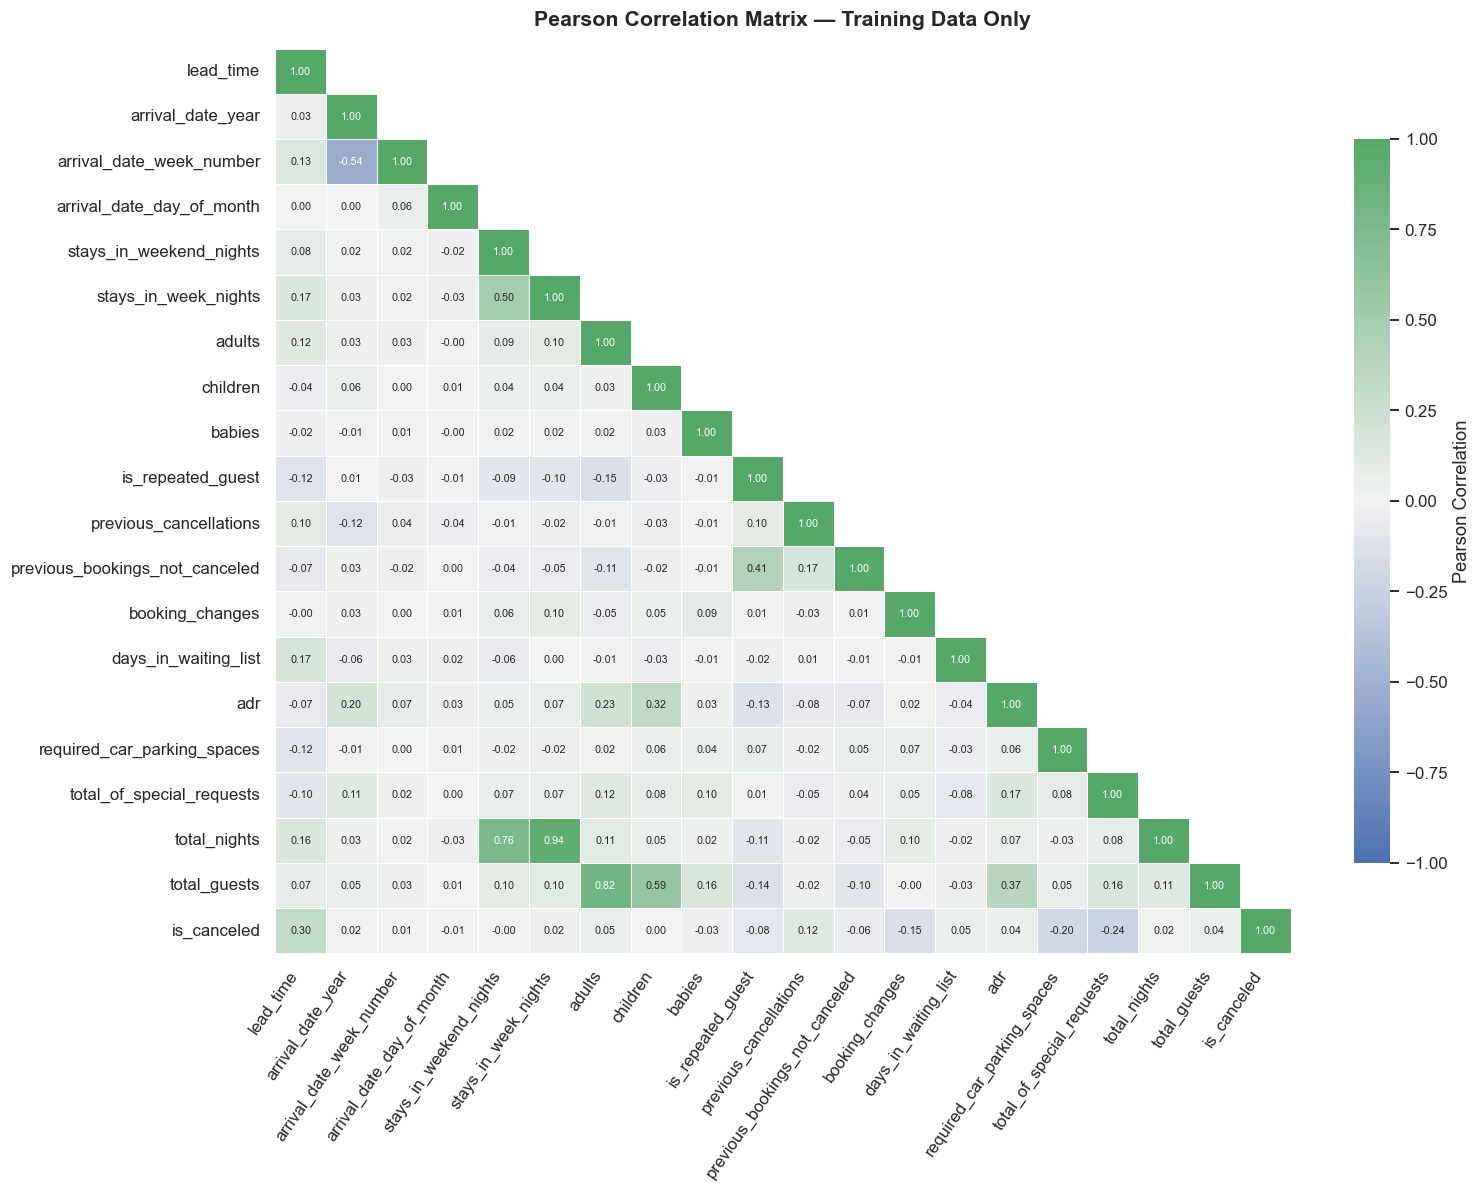

In [8]:
# Explore linear associations using the training partition only.
# The target is binary, so its Pearson correlation with a feature is also
# known as point-biserial correlation.
target = "is_canceled"
train_numeric = X_train.select_dtypes(include="number").copy()
train_numeric[target] = y_train.to_numpy()

# Put the target at the end to make its correlations easier to find.
df_ordered = pd.concat(
    [train_numeric.drop(columns=[target]), train_numeric[[target]]], axis=1
)
corr_matrix = df_ordered.corr(method="pearson")

# Show one triangle only because the matrix is symmetric.
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(14.3, 11))
sns.heatmap(
    corr_matrix, mask=mask, annot=True, fmt=".2f",
    cmap=correlation_cmap, center=0, vmin=-1, vmax=1,
    linewidths=0.5, linecolor="white", square=False,
    annot_kws={"size": 7}, ax=ax,
    cbar_kws={"shrink": 0.80, "label": "Pearson Correlation"},
)
ax.grid(False)
ax.set_title("Pearson Correlation Matrix — Training Data Only", pad=15)
ax.tick_params(axis="x", rotation=55)
for tick in ax.get_xticklabels():
    tick.set_ha("right")
ax.tick_params(axis="y", rotation=0)
fig.tight_layout()
save_figure(fig, "correlation_matrix.png")
plt.show()

## 7. Preprocessing inside a Pipeline

Numeric missing values are filled with the training median. Categorical missing values use the most common training category, followed by one-hot encoding.

I keep these transformations inside a scikit-learn `Pipeline`. During cross-validation, each fold learns its imputation and encoding rules from its own training rows. The encoder also ignores categories it has not seen before, so prediction does not fail when a new category appears.

In [9]:
# Identify column types from the training data, then preprocess each type differently.
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

# Numeric columns: replace missing values with the median.
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
])

# Categorical columns: fill missing values with the most common category,
# then convert categories into 0/1 indicator columns.
# ignore unknown categories so a new test category does not crash prediction.
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])

# ColumnTransformer applies the numeric and categorical steps to the right columns.
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features),
])

print(f"Numeric features: {len(numeric_features)}")
print(f"Categorical features: {len(categorical_features)}")
print("Largest categorical vocabularies in the training set:")
display(
    X_train[categorical_features]
    .nunique(dropna=False)
    .sort_values(ascending=False)
    .head(8)
    .to_frame("Unique values")
)

Numeric features: 19
Categorical features: 10
Largest categorical vocabularies in the training set:


,Unique values
agent,319
country,169
arrival_date_month,12
reserved_room_type,10
market_segment,8
meal,5
distribution_channel,5
customer_type,4


## 8. Establishing useful baselines

I start with a `DummyClassifier` that always predicts the majority class. It gives a reference for accuracy without learning any booking patterns.

Next I fit an unrestricted Decision Tree. I compare its training and held-out F1 scores: a near-perfect training score alongside a noticeably lower test score is a warning that the tree may have memorized details of the training set.

In [10]:
# Baseline 1: predict the most common class for every reservation.
# This tells us how a trivial model performs without learning feature patterns.
dummy_model = DummyClassifier(strategy="most_frequent")
dummy_model.fit(X_train, y_train)
dummy_pred = dummy_model.predict(X_test)

# Baseline 2: use a Decision Tree with no depth/leaf constraints.
# Preprocessing and the tree are one Pipeline so each CV fold learns preprocessing
# only from that fold's training data.
baseline_model = Pipeline([
    ("prep", preprocessor),
    ("tree", DecisionTreeClassifier(random_state=RANDOM_STATE)),
])
baseline_model.fit(X_train, y_train)

baseline_train_pred = baseline_model.predict(X_train)
baseline_test_pred = baseline_model.predict(X_test)

baseline_metrics = evaluate_classifier("Unrestricted tree", y_test, baseline_test_pred)
dummy_metrics = evaluate_classifier("Majority class", y_test, dummy_pred)
print("Held-out metrics:")
display(pd.DataFrame([dummy_metrics, baseline_metrics]).round(4))
print(f"Unrestricted tree — train F1: {f1_score(y_train, baseline_train_pred):.4f}")
print("Baseline test classification report:")
print(classification_report(
    y_test, baseline_test_pred,
    target_names=["Not Cancelled", "Cancelled"], zero_division=0
))

Held-out metrics:


,Model,Accuracy,Precision,Recall,F1
0,Majority class,0.6440,0.0000,0.000,0.0000
1,Unrestricted tree,0.8342,0.7715,0.759,0.7652


Unrestricted tree — train F1: 0.9936
Baseline test classification report:
               precision    recall  f1-score   support

Not Cancelled       0.87      0.88      0.87     15291
    Cancelled       0.77      0.76      0.77      8451

     accuracy                           0.83     23742
    macro avg       0.82      0.82      0.82     23742
 weighted avg       0.83      0.83      0.83     23742



### 8.1 Where the unrestricted tree makes mistakes

The confusion matrix shows both **counts** and **percentages within each actual class**. The dashed outlines mark false positives (unnecessary cancellation alerts) and false negatives (cancellations the model misses). The same 0–100% color scale is used for both trees, making the plots directly comparable.

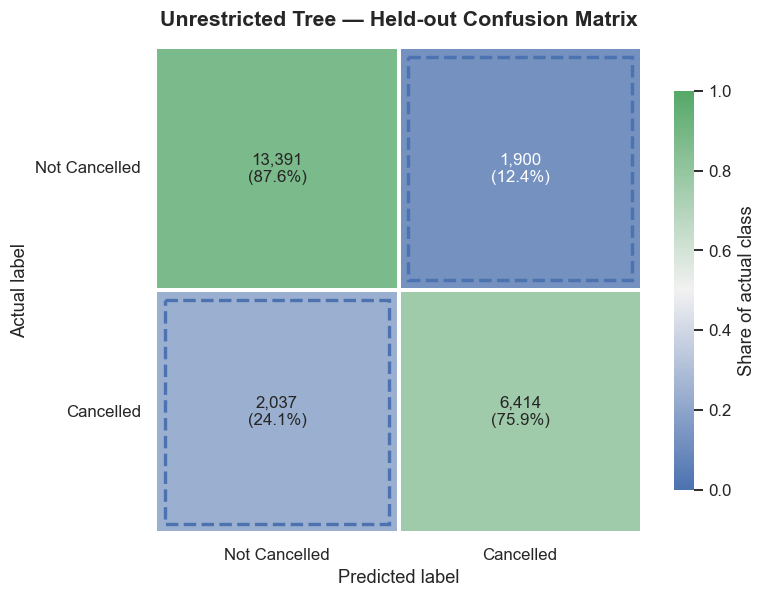

In [11]:
cm_baseline = show_confusion(
    y_test, baseline_test_pred, "Unrestricted Tree — Held-out Confusion Matrix",
    "baseline_confusion_matrix.png"
)

## 9. Tuning with group-aware cross-validation

I compare a small set of tree settings using five grouped folds **inside the training data**. The test set is not used to choose parameters.

The search varies depth, minimum node and leaf sizes, split criterion, and class weighting. I select by mean F1 for the cancellation class, then refit the selected pipeline on all training rows. This is a deliberately limited grid; close CV scores should not be treated as evidence that one setting is universally best.

### 9.1 What each tuned setting controls

| Setting | What it does | Why it matters here |
|---|---|---|
| `max_depth` | Limits the number of questions on any path from root to leaf. | Smaller values give simpler trees; larger values can learn more specific rules. |
| `min_samples_split` | Minimum number of reservations a node needs before it may be split. | Prevents splits on very small groups. |
| `min_samples_leaf` | Minimum number of reservations that must end up in every leaf. | Prevents leaves built on a handful of rows. |
| `criterion` | Impurity measure used to compare splits (`gini` or `entropy`). | Usually gives similar trees; tested for completeness. |
| `class_weight` | `None` treats every row equally; `"balanced"` gives the rarer class (cancelled) more weight. | Can make the tree more willing to predict cancellations, which tends to raise recall. |
| `ccp_alpha` | Cost-complexity pruning strength. | Fixed at 0 here, so pruning is not part of the search. |

These settings are *hyperparameters*: they are chosen before training and compared with cross-validation, rather than learned from the data like the tree's splits.

In [12]:
# These are the tree settings we want to compare.
# max_depth limits how many split levels the tree can learn.
# min_samples_split controls how many rows are needed before a node can split.
# min_samples_leaf prevents leaves that contain too few training examples.
# criterion chooses how split quality is measured; class_weight can emphasize cancellations.
param_grid = {
    "tree__criterion": ["gini", "entropy"],
    "tree__max_depth": [8, 12],
    "tree__min_samples_split": [10, 25],
    "tree__min_samples_leaf": [5, 10],
    "tree__ccp_alpha": [0.0],  # pruning strength is fixed, not tuned in this search
    "tree__class_weight": [None, "balanced"],
}

# Use grouped folds again inside the training data. The test set is not used here.
cv_strategy = StratifiedGroupKFold(
    n_splits=5, shuffle=True, random_state=RANDOM_STATE + 1
)

# Audit each fold: an exact predictor group must not appear in both fold partitions.
for fold_number, (fold_train_idx, fold_valid_idx) in enumerate(
    cv_strategy.split(X_train, y_train, groups_train), start=1
):
    overlap = np.intersect1d(
        groups_train[fold_train_idx], groups_train[fold_valid_idx]
    )
    assert len(overlap) == 0, f"Group overlap found in CV fold {fold_number}."

number_of_candidates = int(np.prod([len(values) for values in param_grid.values()]))
number_of_fits = number_of_candidates * 5
print(f"Grid search: {number_of_candidates} settings × 5 folds = {number_of_fits} model fits")

# GridSearchCV trains each parameter combination on four folds and validates on the fifth.
# F1 is the selection metric because it balances precision and recall for cancellations.
grid_search = GridSearchCV(
    estimator=baseline_model,
    param_grid=param_grid,
    cv=cv_strategy,
    scoring="f1",
    n_jobs=1,
    pre_dispatch=2,
    refit=True,
    return_train_score=True,
    verbose=0,
)
grid_search.fit(X_train, y_train, groups=groups_train)

best_index = grid_search.best_index_
cv_results = pd.DataFrame(grid_search.cv_results_)
print("Best parameters:")
print(json.dumps(grid_search.best_params_, indent=2))
print(f"Best mean grouped-CV F1: {grid_search.best_score_:.4f}")
print(f"Standard deviation across folds: {cv_results.loc[best_index, 'std_test_score']:.4f}")
print("Top five settings:")
display(cv_results.sort_values("rank_test_score")[
    ["rank_test_score", "mean_test_score", "std_test_score", "params"]
].head(5).reset_index(drop=True))

print(
    "This is a deliberately small grid for a readable project. "
    "Each varied parameter has only two tested values, so a wider search "
    "could find a different setting."
)

# The highest-ranked settings can be very close in mean CV F1.
top_five = cv_results.sort_values("rank_test_score").head(5)
top_five_spread = top_five["mean_test_score"].max() - top_five["mean_test_score"].min()
print(
    f"Top-five mean CV F1 spread: {top_five_spread:.4f}; "
    f"best setting's fold SD: {cv_results.loc[best_index, 'std_test_score']:.4f}."
)
print("Small differences between settings may reflect fold-to-fold variation.")


Grid search: 32 settings × 5 folds = 160 model fits
Best parameters:
{
  "tree__ccp_alpha": 0.0,
  "tree__class_weight": "balanced",
  "tree__criterion": "gini",
  "tree__max_depth": 12,
  "tree__min_samples_leaf": 10,
  "tree__min_samples_split": 10
}
Best mean grouped-CV F1: 0.7948
Standard deviation across folds: 0.0054
Top five settings:


,rank_test_score,mean_test_score,std_test_score,params
0,1,0.794842,0.005376,"{'tree__ccp_alpha': 0.0, 'tree__class_weight':..."
1,2,0.794726,0.005174,"{'tree__ccp_alpha': 0.0, 'tree__class_weight':..."
2,3,0.794648,0.005614,"{'tree__ccp_alpha': 0.0, 'tree__class_weight':..."
3,4,0.794487,0.006288,"{'tree__ccp_alpha': 0.0, 'tree__class_weight':..."
4,5,0.794172,0.005490,"{'tree__ccp_alpha': 0.0, 'tree__class_weight':..."


This is a deliberately small grid for a readable project. Each varied parameter has only two tested values, so a wider search could find a different setting.
Top-five mean CV F1 spread: 0.0007; best setting's fold SD: 0.0054.
Small differences between settings may reflect fold-to-fold variation.


## 10. Held-out results and model complexity

With model selection complete, I evaluate both trees on the same held-out fold. Alongside accuracy, precision, recall, and F1, I compare the number of false alerts and missed cancellations.

I also report tree depth, leaf count, and the training–test F1 gap. These help explain *how* the model changed; a smaller gap alone is not proof that it will perform better on future bookings.

In [13]:
# GridSearchCV refits the best configuration on the full training partition.
tuned_model = grid_search.best_estimator_

# Predict the training and held-out test labels with both tree versions.
tuned_train_pred = tuned_model.predict(X_train)
tuned_test_pred = tuned_model.predict(X_test)
tuned_metrics = evaluate_classifier("CV-tuned tree", y_test, tuned_test_pred)

# Compare the dummy model, unrestricted tree, and tuned tree on the same test set.
comparison = pd.DataFrame([dummy_metrics, baseline_metrics, tuned_metrics])
print("Held-out classification metrics:")
display(comparison.round(4))

# The train-test F1 gap is a simple diagnostic for overfitting.
# It is not a guarantee of performance on future years or different hotels.
model_predictions = {
    "Unrestricted tree": (baseline_train_pred, baseline_test_pred),
    "CV-tuned tree": (tuned_train_pred, tuned_test_pred),
}
complexity_rows = []
for model_name, model in [
    ("Unrestricted tree", baseline_model),
    ("CV-tuned tree", tuned_model),
]:
    train_predictions, test_predictions = model_predictions[model_name]
    tree = model.named_steps["tree"]
    train_f1 = f1_score(y_train, train_predictions)
    test_f1 = f1_score(y_test, test_predictions)
    complexity_rows.append({
        "Model": model_name,
        "Train F1": train_f1,
        "Test F1": test_f1,
        "F1 gap": train_f1 - test_f1,
        "Depth": tree.get_depth(),
        "Leaves": tree.get_n_leaves(),
    })
complexity_comparison = pd.DataFrame(complexity_rows)
print("Model complexity and train-test gap:")
display(complexity_comparison.round(4))

print("Tuned test classification report:")
print(classification_report(
    y_test, tuned_test_pred,
    target_names=["Not Cancelled", "Cancelled"], zero_division=0
))

Held-out classification metrics:


,Model,Accuracy,Precision,Recall,F1
0,Majority class,0.6440,0.0000,0.0000,0.0000
1,Unrestricted tree,0.8342,0.7715,0.7590,0.7652
2,CV-tuned tree,0.8465,0.7708,0.8096,0.7897


Model complexity and train-test gap:


,Model,Train F1,Test F1,F1 gap,Depth,Leaves
0,Unrestricted tree,0.9936,0.7652,0.2284,49,9823
1,CV-tuned tree,0.8152,0.7897,0.0254,12,373


Tuned test classification report:
               precision    recall  f1-score   support

Not Cancelled       0.89      0.87      0.88     15291
    Cancelled       0.77      0.81      0.79      8451

     accuracy                           0.85     23742
    macro avg       0.83      0.84      0.83     23742
 weighted avg       0.85      0.85      0.85     23742



### 10.1 Confusion matrix for the tuned tree

This chart uses the same class order, percentages, and color scale as the unrestricted tree's matrix above.

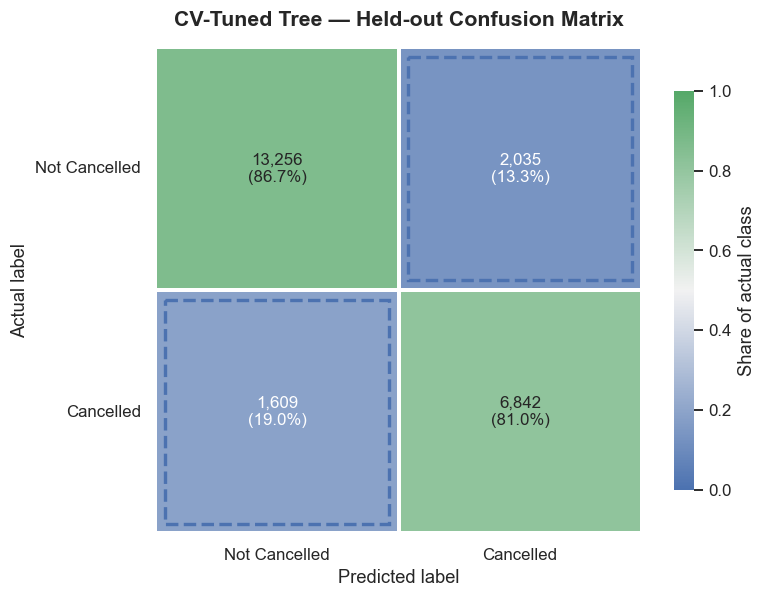

In [14]:
cm_tuned = show_confusion(
    y_test, tuned_test_pred, "CV-Tuned Tree — Held-out Confusion Matrix",
    "tuned_confusion_matrix.png"
)

### 10.2 What changed after tuning?

The first chart compares training and held-out F1. The second shows the practical error trade-off: false alerts versus missed cancellations. Which mistake matters more would depend on how a hotel actually uses the predictions.

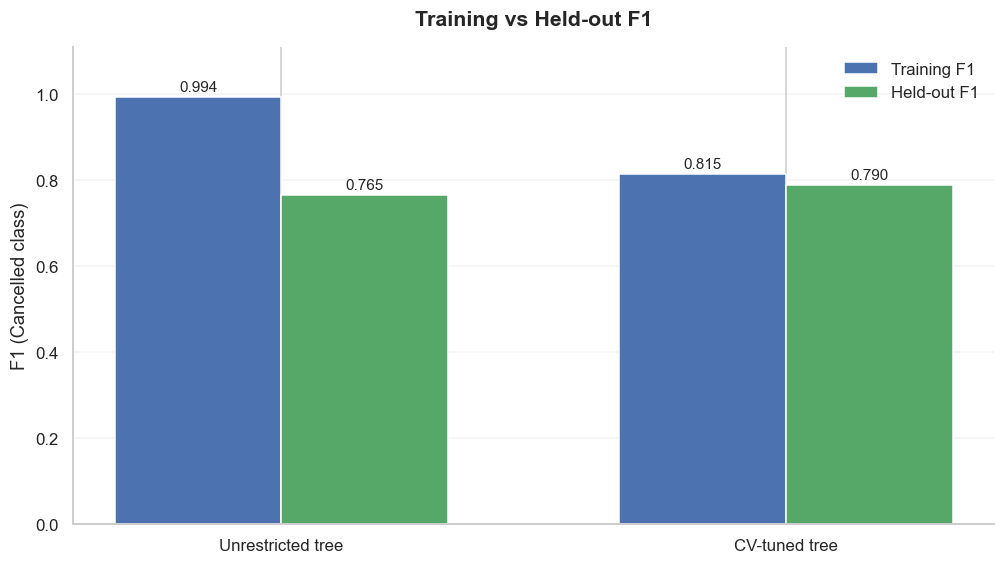

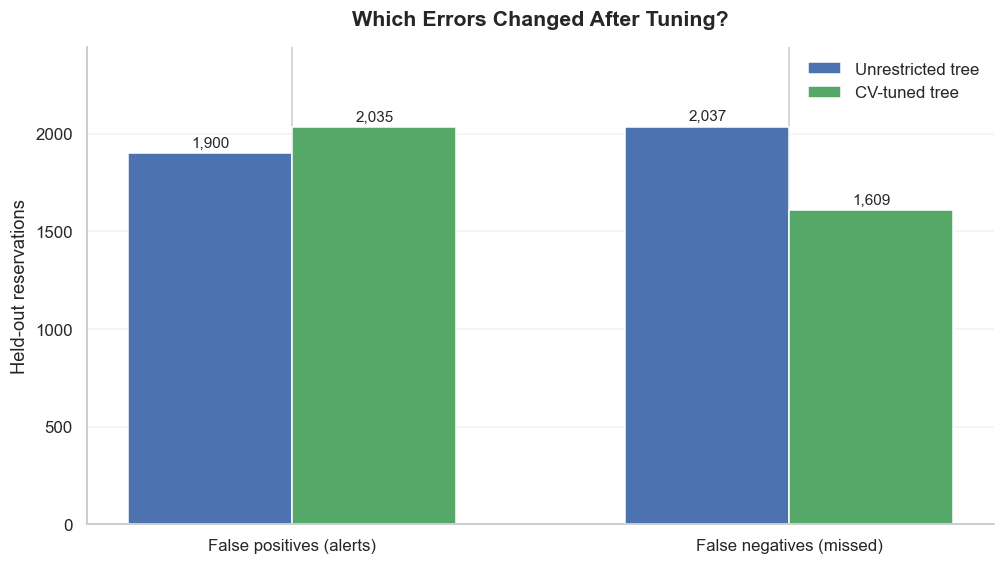

In [15]:
fig, ax = plt.subplots(figsize=(9.3, 5.3))
models = complexity_comparison["Model"].tolist()
x = np.arange(len(models))
width = 0.33
train_bars = ax.bar(x - width / 2, complexity_comparison["Train F1"],
                    width, color=PRIMARY, label="Training F1")
test_bars = ax.bar(x + width / 2, complexity_comparison["Test F1"],
                   width, color=SECONDARY, label="Held-out F1")
for bar in [*train_bars, *test_bars]:
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.013,
            f"{bar.get_height():.3f}", ha="center", fontsize=10)
ax.set_xticks(x, models)
ax.set_ylim(0, 1.11)
ax.set_ylabel("F1 (Cancelled class)")
ax.set_title("Training vs Held-out F1", pad=14)
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
save_figure(fig, "train_test_f1_comparison.png")
plt.show()

fig, ax = plt.subplots(figsize=(9.3, 5.3))
error_names = ["False positives (alerts)", "False negatives (missed)"]
x = np.arange(2)
base_errors = [int(cm_baseline[0, 1]), int(cm_baseline[1, 0])]
tuned_errors = [int(cm_tuned[0, 1]), int(cm_tuned[1, 0])]
base_bars = ax.bar(x - width / 2, base_errors, width,
                   color=PRIMARY, label="Unrestricted tree")
tuned_bars = ax.bar(x + width / 2, tuned_errors, width,
                    color=SECONDARY, label="CV-tuned tree")
for bar in [*base_bars, *tuned_bars]:
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + max(base_errors + tuned_errors) * 0.015,
            f"{bar.get_height():,.0f}", ha="center", fontsize=10)
ax.set_xticks(x, error_names)
ax.set_ylim(0, max(base_errors + tuned_errors) * 1.20)
ax.set_ylabel("Held-out reservations")
ax.set_title("Which Errors Changed After Tuning?", pad=14)
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
save_figure(fig, "error_tradeoff.png")
plt.show()

### 10.3 How uncertain is the F1 difference?

I use a **paired group bootstrap** as an additional check. Each resample draws complete predictor groups from the held-out set, then recalculates the difference in F1 between the two already-fitted trees. The 95% interval describes variation within this held-out sample; it does not include uncertainty from retraining, future periods, or different hotels.

In [16]:
# Optional robustness check: estimate uncertainty in the difference between the two F1 scores.
# We resample whole predictor groups, not individual rows, because identical predictor
# patterns were kept together in the hold-out split.
bootstrap_data = pd.DataFrame({
    "group": groups_test,
    "actual": y_test.to_numpy(),
    "baseline_prediction": baseline_test_pred,
    "tuned_prediction": tuned_test_pred,
})

# For each group, count the true positives, false positives, and false negatives
# for both models. F1 can be calculated from these counts.
for model_name, prediction_column in [
    ("baseline", "baseline_prediction"),
    ("tuned", "tuned_prediction"),
]:
    prediction = bootstrap_data[prediction_column]
    actual = bootstrap_data["actual"]
    bootstrap_data[f"{model_name}_tp"] = ((actual == 1) & (prediction == 1)).astype(int)
    bootstrap_data[f"{model_name}_fp"] = ((actual == 0) & (prediction == 1)).astype(int)
    bootstrap_data[f"{model_name}_fn"] = ((actual == 1) & (prediction == 0)).astype(int)

count_columns = [
    f"{model}_{kind}"
    for model in ["baseline", "tuned"]
    for kind in ["tp", "fp", "fn"]
]
group_counts = bootstrap_data.groupby("group", sort=False)[count_columns].sum().to_numpy(dtype=np.int64)

# Each bootstrap draw samples as many groups as the test set contains, with replacement.
# The 2.5th and 97.5th percentiles form a percentile-based 95% interval.
rng = np.random.default_rng(RANDOM_STATE)
bootstrap_deltas = np.empty(2000)
for draw in range(len(bootstrap_deltas)):
    sampled_group_indices = rng.integers(0, len(group_counts), size=len(group_counts))
    tp_base, fp_base, fn_base, tp_tuned, fp_tuned, fn_tuned = group_counts[sampled_group_indices].sum(axis=0)
    f1_base = 2 * tp_base / max(1, 2 * tp_base + fp_base + fn_base)
    f1_tuned = 2 * tp_tuned / max(1, 2 * tp_tuned + fp_tuned + fn_tuned)
    bootstrap_deltas[draw] = f1_tuned - f1_base

f1_delta = tuned_metrics["F1"] - baseline_metrics["F1"]
f1_delta_ci = np.quantile(bootstrap_deltas, [0.025, 0.975])
print(f"Tuned minus unrestricted test F1: {f1_delta:+.4f}")
print(f"Paired group-bootstrap 95% interval: [{f1_delta_ci[0]:+.4f}, {f1_delta_ci[1]:+.4f}]")
print(f"Bootstrap draws: {len(bootstrap_deltas):,}")
print("This interval is conditional on this test split; it does not measure future time drift or transfer to another hotel.")

Tuned minus unrestricted test F1: +0.0245
Paired group-bootstrap 95% interval: [+0.0141, +0.0346]
Bootstrap draws: 2,000
This interval is conditional on this test split; it does not measure future time drift or transfer to another hotel.


### 10.4 Key results

The next table is built from the metrics calculated in this run. Keeping the summary in code avoids leaving old scores in the notebook after the data or split changes.

In [17]:
# Build the summary from the current run, so the prose stays aligned with the outputs.
tn_base, fp_base, fn_base, tp_base = cm_baseline.ravel()
tn_tuned, fp_tuned, fn_tuned, tp_tuned = cm_tuned.ravel()
base_complexity = complexity_comparison.loc[
    complexity_comparison["Model"] == "Unrestricted tree"
].iloc[0]
tuned_complexity = complexity_comparison.loc[
    complexity_comparison["Model"] == "CV-tuned tree"
].iloc[0]

summary_md = f"""### Key results

| Metric | Unrestricted tree | CV-tuned tree |
|---|---:|---:|
| Test F1 (Cancelled) | {baseline_metrics['F1']:.4f} | **{tuned_metrics['F1']:.4f}** |
| Test precision | {baseline_metrics['Precision']:.4f} | {tuned_metrics['Precision']:.4f} |
| Test recall | {baseline_metrics['Recall']:.4f} | {tuned_metrics['Recall']:.4f} |
| False alerts (FP) | {fp_base:,} | {fp_tuned:,} |
| Missed cancellations (FN) | {fn_base:,} | {fn_tuned:,} |
| Depth / leaves | {int(base_complexity['Depth'])} / {int(base_complexity['Leaves']):,} | {int(tuned_complexity['Depth'])} / {int(tuned_complexity['Leaves']):,} |

The tuned tree's held-out F1 difference is **{f1_delta:+.4f}** (paired predictor-group bootstrap 95% interval: **[{f1_delta_ci[0]:+.4f}, {f1_delta_ci[1]:+.4f}]**, {len(bootstrap_deltas):,} resamples). The interval is conditional on this one held-out partition, so it should be read as a within-split uncertainty summary rather than a guarantee about future bookings.
"""
display(Markdown(summary_md))

### Key results

| Metric | Unrestricted tree | CV-tuned tree |
|---|---:|---:|
| Test F1 (Cancelled) | 0.7652 | **0.7897** |
| Test precision | 0.7715 | 0.7708 |
| Test recall | 0.7590 | 0.8096 |
| False alerts (FP) | 1,900 | 2,035 |
| Missed cancellations (FN) | 2,037 | 1,609 |
| Depth / leaves | 49 / 9,823 | 12 / 373 |

The tuned tree's held-out F1 difference is **+0.0245** (paired predictor-group bootstrap 95% interval: **[+0.0141, +0.0346]**, 2,000 resamples). The interval is conditional on this one held-out partition, so it should be read as a within-split uncertainty summary rather than a guarantee about future bookings.


## 11. Looking inside the tuned tree

The complete tree is too large to display clearly, so I plot only its first four levels (depths 0–3). These early splits show the broad decisions the tree makes. The actual model still uses the full fitted tree when predicting.

Blue and green node fills indicate the predicted class; the lighter and darker shades reflect the purity of the nodes.

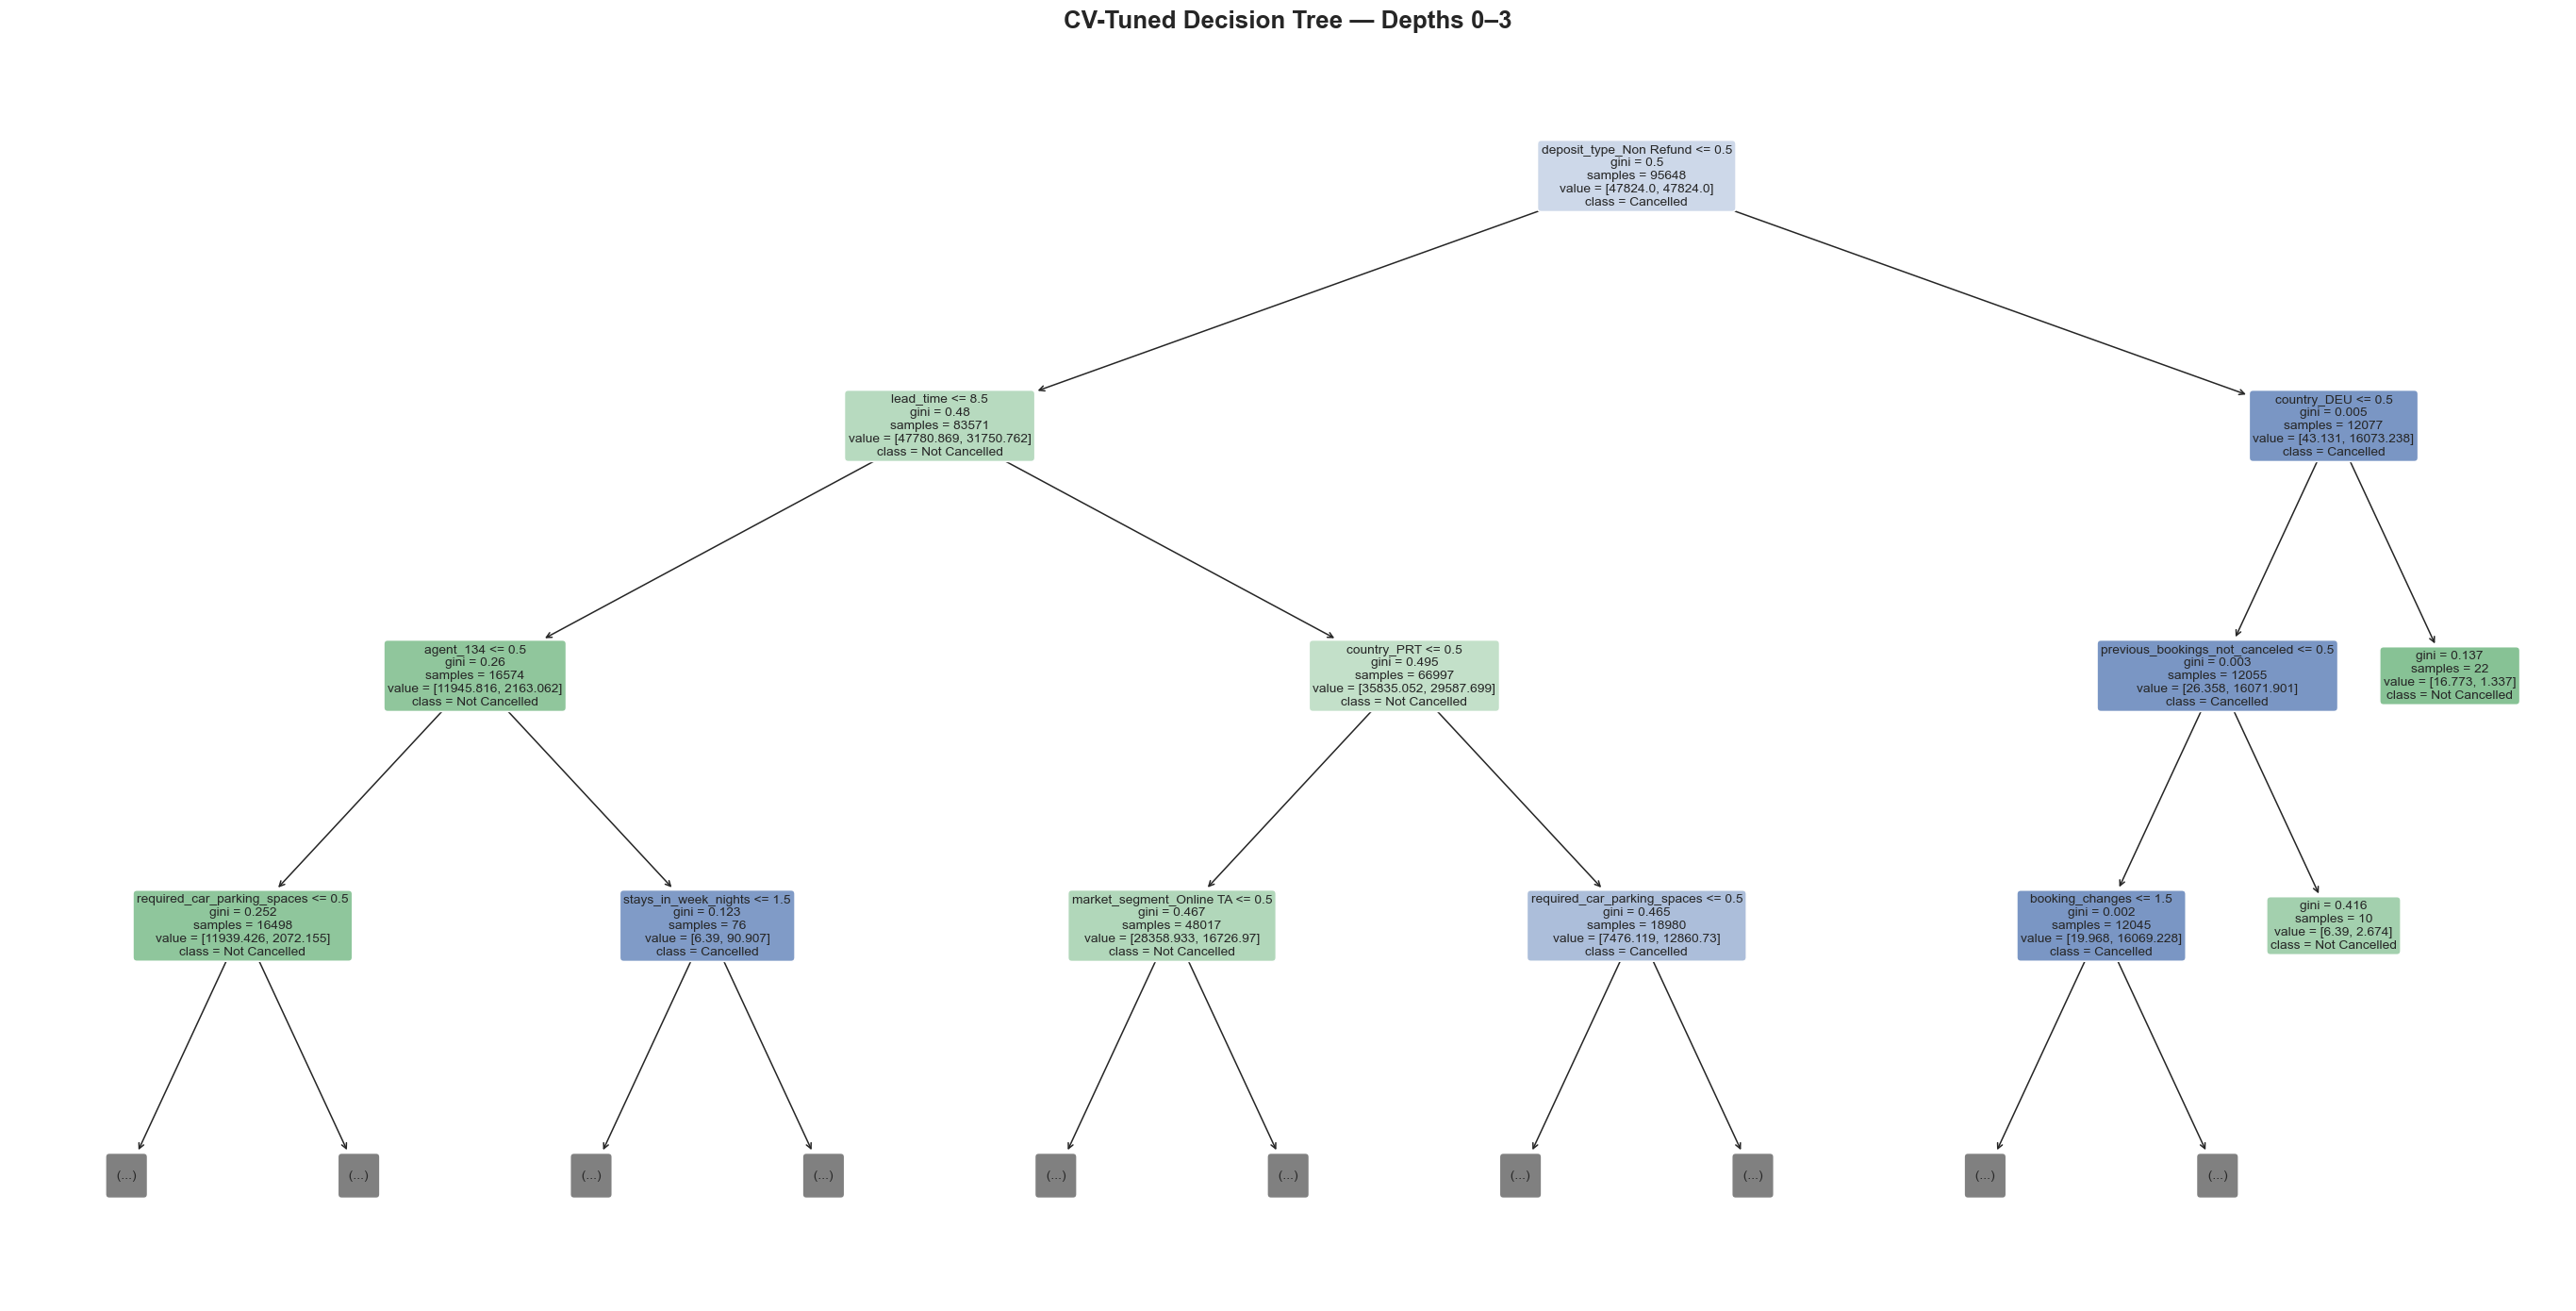

First split feature: deposit_type_Non Refund
The chart is truncated for readability; prediction uses the full fitted tree.


In [18]:
# A full tree with hundreds of leaves is too large to read on one page.
# Show only the first four levels; the fitted model still uses all its levels for prediction.
tuned_tree = tuned_model.named_steps["tree"]
feature_names = tuned_model.named_steps["prep"].get_feature_names_out()
clean_feature_names = [
    name.replace("num__", "").replace("cat__", "")
    for name in feature_names
]

fig, ax = plt.subplots(figsize=(25, 12.8))
artists = plot_tree(
    tuned_tree,
    feature_names=clean_feature_names,
    class_names=["Not Cancelled", "Cancelled"],
    filled=True,
    max_depth=3,
    fontsize=9,
    rounded=True,
    ax=ax,
)

# Recolor the nodes to match the portfolio palette. This affects appearance only.
for artist in artists:
    patch = artist.get_bbox_patch()
    if patch is None:
        continue
    node_text = artist.get_text()
    original_color = patch.get_facecolor()
    if "class = Not Cancelled" in node_text:
        base_rgb = np.asarray(to_rgb(SECONDARY))
    elif "class = Cancelled" in node_text:
        base_rgb = np.asarray(to_rgb(PRIMARY))
    else:
        continue
    saturation = colorsys.rgb_to_hsv(*original_color[:3])[1]
    strength = float(np.clip(0.28 + 0.62 * saturation, 0.28, 0.90))
    shade = (1 - strength) * np.ones(3) + strength * base_rgb
    patch.set_facecolor((*shade, original_color[3]))

ax.set_title("CV-Tuned Decision Tree — Depths 0–3", fontsize=17, pad=16)
fig.tight_layout()
save_figure(fig, "tuned_tree_depth_0_to_3.png")
plt.show()

root_feature = clean_feature_names[tuned_tree.tree_.feature[0]]
print("First split feature:", root_feature)
print("The chart is truncated for readability; prediction uses the full fitted tree.")

## 12. Which features did the tree use?

Impurity-based feature importance measures how much each encoded feature contributed to reducing impurity in this fitted tree. It is useful for understanding the model, but it is **not a causal explanation**. Features with many possible split points can receive more importance, and correlated features can share or compete for credit.

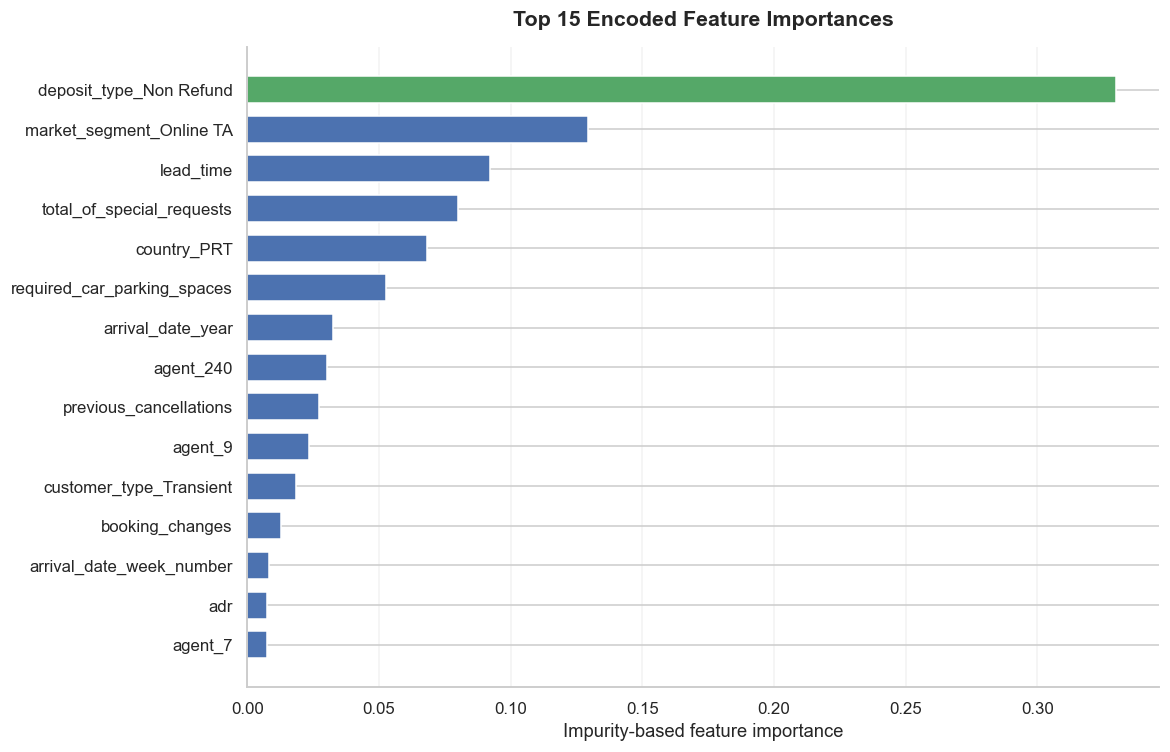

Top five features (descriptive, not causal):


,Feature,Importance
0,deposit_type_Non Refund,0.3298
1,market_segment_Online TA,0.1295
2,lead_time,0.0922
3,total_of_special_requests,0.0799
4,country_PRT,0.0684


**Interpretation:** `deposit_type_Non Refund` is the first split in this fitted tree. That shows a strong pattern in this dataset, but it does not prove that the deposit type causes cancellation. The feature may reflect booking rules and how reservations are recorded.

In [19]:
# Feature importance describes how much each encoded feature reduced impurity
# across the fitted tree. It is useful for inspection, but it is not causal evidence.
importance_df = pd.DataFrame({
    "Feature": clean_feature_names,
    "Importance": tuned_tree.feature_importances_,
}).sort_values("Importance", ascending=False)

top_importances = importance_df.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(10.8, 7))
bar_colors = [
    SECONDARY if feature == importance_df.iloc[0]["Feature"] else PRIMARY
    for feature in top_importances["Feature"]
]
ax.barh(
    top_importances["Feature"],
    top_importances["Importance"],
    color=bar_colors,
    height=0.68,
)
ax.set_xlabel("Impurity-based feature importance")
ax.set_title("Top 15 Encoded Feature Importances", pad=14)
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
save_figure(fig, "feature_importances.png")
plt.show()

print("Top five features (descriptive, not causal):")
display(importance_df.head(5).round(4).reset_index(drop=True))

if root_feature == "deposit_type_Non Refund":
    display(Markdown(
        "**Interpretation:** `deposit_type_Non Refund` is the first split in this fitted tree. "
        "That shows a strong pattern in this dataset, but it does not prove that the deposit type causes cancellation. "
        "The feature may reflect booking rules and how reservations are recorded."
    ))
else:
    display(Markdown(
        f"**Interpretation:** `{root_feature}` is the first split in this fitted tree. "
        "A first split describes how the model separates this dataset; it is not proof of cause and effect."
    ))

## 13. Interpreting the results

The interpretation below is generated from the current predictions, confusion matrices, and selected parameters. This matters because a different group split or library version can change both the scores and the balance between precision and recall.

In [20]:
# Describe the observed changes using the scores and errors from this run.
precision_change = tuned_metrics["Precision"] - baseline_metrics["Precision"]
recall_change = tuned_metrics["Recall"] - baseline_metrics["Recall"]
fp_change = int(fp_tuned - fp_base)
fn_change = int(fn_tuned - fn_base)

def error_change(label, change):
    if change < 0:
        return f"{label} decreased by {-change:,}"
    if change > 0:
        return f"{label} increased by {change:,}"
    return f"{label} did not change"

if recall_change > 0.02 and abs(precision_change) < 0.015:
    main_change = "Most of the change is in recall: the tuned tree catches more cancellations."
elif precision_change > 0.02 and abs(recall_change) < 0.015:
    main_change = "Most of the change is in precision: a larger share of cancellation alerts is correct."
else:
    main_change = "Precision and recall both contribute to the overall F1 comparison."

selected_weight = grid_search.best_params_["tree__class_weight"]
if selected_weight == "balanced":
    weight_note = (
        "The selected tree uses `class_weight='balanced'`, giving the classes "
        "more equal total weight during fitting. That may affect the error trade-off, "
        "but this comparison does not isolate the effect of class weighting."
    )
else:
    weight_note = (
        "The selected tree uses `class_weight=None`; its performance change "
        "should not be attributed to class reweighting."
    )

if f1_delta > 0:
    f1_statement = "improved"
elif f1_delta < 0:
    f1_statement = "declined"
else:
    f1_statement = "did not change"

base_gap = float(base_complexity["F1 gap"])
tuned_gap = float(tuned_complexity["F1 gap"])

interpretation = f"""
**On this grouped held-out test**, F1 {f1_statement} from **{baseline_metrics['F1']:.4f}**
to **{tuned_metrics['F1']:.4f}** (change **{f1_delta:+.4f}**).
Precision changed from {baseline_metrics['Precision']:.4f} to {tuned_metrics['Precision']:.4f}
({precision_change:+.4f}); recall changed from {baseline_metrics['Recall']:.4f}
to {tuned_metrics['Recall']:.4f} ({recall_change:+.4f}). {main_change}

In terms of actual reservations, {error_change('false alerts', fp_change)}
and {error_change('missed cancellations', fn_change)}. {weight_note}

The tuned tree has **{int(tuned_complexity['Leaves']):,} leaves**, compared with
{int(base_complexity['Leaves']):,} for the unrestricted tree. Its training–test F1
gap is {tuned_gap:.4f}, versus {base_gap:.4f} for the unrestricted tree.
The paired predictor-group bootstrap interval for the F1 difference is
**[{f1_delta_ci[0]:+.4f}, {f1_delta_ci[1]:+.4f}]** from
{len(bootstrap_deltas):,} resamples.

**How far can I take this result?** The groups are defined by identical predictor
values, not known reservation IDs. There is no chronological test or external-hotel
validation, and some retained features may change before arrival. The data covers
2015–2017; `arrival_date_year` and related calendar or pricing fields may capture
period-specific patterns. The strong `deposit_type_Non Refund` signal may also
reflect booking policies and recording practices rather than a causal effect.
"""
display(Markdown(interpretation))



**On this grouped held-out test**, F1 improved from **0.7652**
to **0.7897** (change **+0.0245**).
Precision changed from 0.7715 to 0.7708
(-0.0007); recall changed from 0.7590
to 0.8096 (+0.0506). Most of the change is in recall: the tuned tree catches more cancellations.

In terms of actual reservations, false alerts increased by 135
and missed cancellations decreased by 428. The selected tree uses `class_weight='balanced'`, giving the classes more equal total weight during fitting. That may affect the error trade-off, but this comparison does not isolate the effect of class weighting.

The tuned tree has **373 leaves**, compared with
9,823 for the unrestricted tree. Its training–test F1
gap is 0.0254, versus 0.2284 for the unrestricted tree.
The paired predictor-group bootstrap interval for the F1 difference is
**[+0.0141, +0.0346]** from
2,000 resamples.

**How far can I take this result?** The groups are defined by identical predictor
values, not known reservation IDs. There is no chronological test or external-hotel
validation, and some retained features may change before arrival. The data covers
2015–2017; `arrival_date_year` and related calendar or pricing fields may capture
period-specific patterns. The strong `deposit_type_Non Refund` signal may also
reflect booking policies and recording practices rather than a causal effect.


## 14. What I learned

The unrestricted tree illustrates how easy it is to fit training examples almost perfectly without achieving the same performance on unseen predictor groups. Limiting its complexity makes the rules easier to inspect, but I still need to check whether the changes improve the errors that matter.

The repeated records also changed how I approached evaluation. Rather than assuming identical rows were mistakes or separate guests, I kept them together when splitting the data. Finally, the feature-importance plot helped me distinguish a pattern the model uses from a reason a guest might cancel.

## 15. Next steps

- Test on a later period to see how the model handles changing booking patterns.
- Define an exact prediction time and keep only fields available at that point.
- Check how results change without `arrival_date_year` and with different treatments of rare `agent` and `country` values.
- Compare a Random Forest or gradient-boosted model under the same evaluation protocol.
- Choose a decision threshold using the real costs of missed cancellations and false alerts.

## 16. Reproducing the analysis

The plotting cells save nine figures to the project's dedicated `images/` folder. At the start of a run, the notebook clears existing PNG files from that folder to prevent old charts from being mixed with new ones. Keep unrelated graphics in a separate folder, such as `assets/`.

This streamlined version **does not write `docs/run_metrics.json` or run a final nine-file verification cell**. The accompanying project package includes `docs/run_metrics.json`, a static snapshot of the saved results. The notebook does not create or update that file when rerun. If you rerun the analysis and publish new results, update the README and documentation to match the new outputs.

A fixed random seed makes the workflow more repeatable, but different package versions or input data can still affect the results.

**Source dataset:** [Hotel Booking Demand](https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand)  
**GitHub project:** [hotel-booking-cancellation-decision-tree](https://github.com/anahitapouladi/hotel-booking-cancellation-decision-tree)  
**Kaggle project:** [hotel-booking-cancellation-decision-tree](https://www.kaggle.com/code/anahitapouladi/hotel-booking-cancellation-decision-tree)